# Session 13: Data Processing Techniques for Machine Learning

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + ['flask', 'requests', 'beautifulsoup4', 'lxml', 'scikit-learn', 'seaborn'], check=False)
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/04-application-based-programming-in-python/code/'
    for f in []:
        if not os.path.exists(f):
            os.makedirs(os.path.dirname(f) or '.', exist_ok=True)
            subprocess.run(['wget', '-q', '-O', f, base + f], check=False)
print('ready')

ready


## Example: `session-13_missing_and_encoding.py`

In [2]:
"""
Session 13 · Example 1: missing values and categorical encoding
---------------------------------------------------------------
Machine-learning models need a complete, NUMERIC table. This example
shows how to (1) find and fill missing values and (2) turn text categories
into numbers with pandas and scikit-learn.
Run:  python session-13_missing_and_encoding.py
"""
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder

pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)
df = pd.DataFrame({
    "age":       [24, 31, np.nan, 45, 29, 38, np.nan, 52],
    "income_k":  [55, 80, 62, np.nan, 48, 120, 70, 95],          # monthly income, thousand Rs
    "city":      ["Karachi", "Lahore", "Karachi", np.nan, "Islamabad", "Karachi", "Lahore", "Karachi"],
    "education": ["Bachelors", "Masters", "Intermediate", "Masters", "Bachelors", "PhD", "Bachelors", np.nan],
    "bought":    ["no", "yes", "no", "yes", "no", "yes", "no", "yes"],   # the target to predict
})
print("raw data:\n", df, "\n")

# 1. Detect missing values
print("missing per column:", df.isna().sum().to_dict())
print(f"rows with any missing value: {df.isna().any(axis=1).sum()} of {len(df)}")

# 2. Option A: drop (only when few rows are affected and they are missing at random)
print("dropna would keep", len(df.dropna()), "rows - too much data lost here")

# 3. Option B: impute. Numbers -> median (robust to outliers); categories -> most frequent
num_cols, cat_cols = ["age", "income_k"], ["city", "education"]
filled = df.copy()
filled[num_cols] = SimpleImputer(strategy="median").fit_transform(df[num_cols])
filled[cat_cols] = SimpleImputer(strategy="most_frequent").fit_transform(df[cat_cols])
print("medians used:", df[num_cols].median().to_dict(), "| modes used:", df[cat_cols].mode().iloc[0].to_dict())
# A missing-indicator column keeps the information that a value WAS missing
filled["age_was_missing"] = df["age"].isna().astype(int)
print("\nafter imputation:\n", filled, "\n")

# 4. Encoding categories
# 4a. NOMINAL (no order): one-hot encoding -> one 0/1 column per category
print("pandas get_dummies:\n", pd.get_dummies(filled["city"], prefix="city", dtype=int).head(4), "\n")
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
city_matrix = ohe.fit_transform(filled[["city"]])
print("OneHotEncoder categories:", ohe.categories_[0].tolist())
print("unknown city 'Quetta' encodes to:", ohe.transform(pd.DataFrame({"city": ["Quetta"]})).tolist(), "(all zeros, no crash)")

# 4b. ORDINAL (natural order): map to ordered integers
levels = [["Intermediate", "Bachelors", "Masters", "PhD"]]
filled["education_level"] = OrdinalEncoder(categories=levels).fit_transform(filled[["education"]]).ravel()
print("\neducation -> level:", dict(zip(filled["education"], filled["education_level"])))

# 4c. TARGET labels: LabelEncoder (for y only)
le = LabelEncoder()
y = le.fit_transform(filled["bought"])
print("target classes:", le.classes_.tolist(), "-> y =", y.tolist())

# 5. The final all-numeric feature matrix X
X = pd.concat([filled[["age", "income_k", "age_was_missing", "education_level"]],
               pd.DataFrame(city_matrix, columns=ohe.get_feature_names_out(), index=filled.index)], axis=1)
print("\nfeature matrix X:", X.shape, "\n", X.round(1))

raw data:
     age  income_k       city     education bought
0  24.0      55.0    Karachi     Bachelors     no
1  31.0      80.0     Lahore       Masters    yes
2   NaN      62.0    Karachi  Intermediate     no
3  45.0       NaN        NaN       Masters    yes
4  29.0      48.0  Islamabad     Bachelors     no
5  38.0     120.0    Karachi           PhD    yes
6   NaN      70.0     Lahore     Bachelors     no
7  52.0      95.0    Karachi           NaN    yes 

missing per column: {'age': 2, 'income_k': 1, 'city': 1, 'education': 1, 'bought': 0}
rows with any missing value: 4 of 8
dropna would keep 4 rows - too much data lost here
medians used: {'age': 34.5, 'income_k': 70.0} | modes used: {'city': 'Karachi', 'education': 'Bachelors'}

after imputation:
     age  income_k       city     education bought  age_was_missing
0  24.0      55.0    Karachi     Bachelors     no                0
1  31.0      80.0     Lahore       Masters    yes                0
2  34.5      62.0    Karachi  Interme

## Example: `session-13_scaling_outliers.py`

In [3]:
"""
Session 13 · Example 2: feature scaling, outliers and feature engineering
-------------------------------------------------------------------------
Run:  python session-13_scaling_outliers.py
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

rng = np.random.default_rng(5)
df = pd.DataFrame({
    "area_sqft": rng.normal(1200, 300, 200).round(),
    "rooms": rng.integers(1, 6, 200),
    "price_m": np.r_[rng.lognormal(3.0, 0.45, 196), [210, 260, 300, 380]].round(1),   # 4 luxury outliers
})
print("raw scales:\n", df.describe().loc[["mean", "std", "min", "max"]].round(1), "\n")

# 1. Why scale? Distance-based models (k-NN, k-means, SVM) and gradient descent
#    are dominated by the column with the biggest numbers.
a, b = df.iloc[0], df.iloc[1]
print(f"distance between rows 0 and 1: {np.linalg.norm(a - b):.1f} "
      f"(area difference {abs(a.area_sqft - b.area_sqft):.0f} swamps rooms difference {abs(a.rooms - b.rooms)})")

# 2. Three scalers
scaled = {name: pd.DataFrame(s.fit_transform(df), columns=df.columns)
          for name, s in [("StandardScaler", StandardScaler()), ("MinMaxScaler", MinMaxScaler()), ("RobustScaler", RobustScaler())]}
for name, d in scaled.items():
    print(f"{name:<15} price: mean {d.price_m.mean():6.2f}  std {d.price_m.std():5.2f}  "
          f"min {d.price_m.min():6.2f}  max {d.price_m.max():6.2f}")

# 3. Outliers: detect with IQR (Statistics module), then decide: keep, cap or remove
q1, q3 = df["price_m"].quantile([0.25, 0.75]); iqr = q3 - q1
upper = q3 + 1.5 * iqr
out = df[df["price_m"] > upper]
print(f"\nIQR fence: price > {upper:.1f} M is an outlier -> {len(out)} rows: {out['price_m'].tolist()}")
capped = df["price_m"].clip(upper=upper)                     # winsorising / capping
logged = np.log1p(df["price_m"])                              # log transform compresses the tail
print(f"skewness: raw {df['price_m'].skew():.2f}, capped {capped.skew():.2f}, log {logged.skew():.2f}")

# 4. Feature engineering: create more useful columns from existing ones
df["price_per_sqft_k"] = (df["price_m"] * 1000 / df["area_sqft"]).round(2)
df["size_band"] = pd.cut(df["area_sqft"], bins=[0, 900, 1400, np.inf], labels=["small", "medium", "large"])
print("\nengineered features:\n", df[["area_sqft", "price_m", "price_per_sqft_k", "size_band"]].head(5))
print("size bands:", df["size_band"].value_counts().to_dict())

fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
ax[0].hist(df["price_m"], bins=30, color="#F43F5E"); ax[0].set_title("raw price (skewed + outliers)")
ax[1].hist(scaled["StandardScaler"]["price_m"], bins=30, color="#FF6B1A"); ax[1].set_title("StandardScaler: same shape")
ax[2].hist(scaled["MinMaxScaler"]["price_m"], bins=30, color="#A78BFA"); ax[2].set_title("MinMax: squeezed by outliers")
ax[3].hist(logged, bins=30, color="#FCD34D"); ax[3].set_title("log1p: tail compressed")
fig.tight_layout(); fig.savefig("session-13_scaling_outliers.png", dpi=95)
print("\nSaved session-13_scaling_outliers.png")

raw scales:
       area_sqft  rooms  price_m
mean     1180.5    3.0     27.7
std       289.3    1.4     39.4
min       483.0    1.0      6.0
max      2008.0    5.0    380.0 

distance between rows 0 and 1: 156.0 (area difference 156 swamps rooms difference 2.0)
StandardScaler  price: mean   0.00  std  1.00  min  -0.55  max   8.97
MinMaxScaler    price: mean   0.06  std  0.11  min   0.00  max   1.00
RobustScaler    price: mean   0.45  std  3.02  min  -1.21  max  27.50

IQR fence: price > 47.7 M is an outlier -> 7 rows: [51.4, 49.7, 49.6, 210.0, 260.0, 300.0, 380.0]
skewness: raw 6.85, capped 0.82, log 1.91

engineered features:
    area_sqft  price_m  price_per_sqft_k size_band
0      959.0     13.4             13.97    medium
1      803.0     13.6             16.94     small
2     1125.0     21.6             19.20    medium
3     1326.0     28.1             21.19    medium
4     1541.0     15.4              9.99     large
size bands: {'medium': 121, 'large': 43, 'small': 36}



Saved session-13_scaling_outliers.png


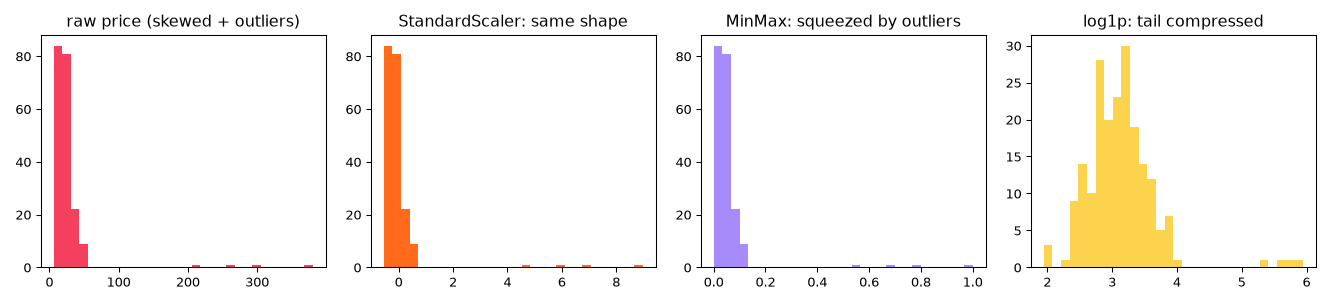

In [4]:
from IPython.display import Image, display
display(Image(filename='session-13_scaling_outliers.png'))  # chart saved by the cell above

## Example: `session-13_pipeline_and_leakage.py`

In [5]:
"""
Session 13 · Example 3: train/test split, Pipeline + ColumnTransformer, and data leakage
--------------------------------------------------------------------------------------
Rule: learn every preprocessing step (medians, scaling, categories) from the
TRAINING data only, then apply the same learned steps to the test data.
A scikit-learn Pipeline does this automatically.
Run:  python session-13_pipeline_and_leakage.py
"""
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

rng = np.random.default_rng(13)
n = 500
df = pd.DataFrame({
    "age": rng.integers(18, 65, n).astype(float),
    "income_k": rng.lognormal(4.2, 0.4, n).round(1),
    "city": rng.choice(["Karachi", "Lahore", "Islamabad", "Peshawar"], n, p=[0.45, 0.3, 0.15, 0.1]),
    "visits": rng.poisson(4, n).astype(float),
})
logit = -6 + 0.04 * df["age"] + 0.03 * df["income_k"] + 0.25 * df["visits"] + (df["city"] == "Islamabad") * 0.8
df["bought"] = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
for col, k in [("age", 30), ("income_k", 25), ("city", 20)]:           # punch random holes
    df.loc[rng.choice(n, k, replace=False), col] = np.nan
print(df.head(), "\nmissing:", df.isna().sum().to_dict(), "| bought rate:", round(df["bought"].mean(), 2))

X, y = df.drop(columns="bought"), df["bought"]
# 1. Split FIRST. stratify keeps the same class balance in both parts; random_state = reproducible
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(f"\ntrain {X_train.shape}, test {X_test.shape}, positive rate train {y_train.mean():.2f} / test {y_test.mean():.2f}")

# 2. Different steps for different column types
numeric = ["age", "income_k", "visits"]
categorical = ["city"]
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical),
])
model = Pipeline([("prep", preprocess), ("clf", LogisticRegression(max_iter=1000))])

# 3. fit() learns medians, means/stds, categories AND the model - from training data only
model.fit(X_train, y_train)
medians = model.named_steps["prep"].named_transformers_["num"].named_steps["impute"].statistics_
print("learned medians (train only):", {c: round(float(m), 1) for c, m in zip(numeric, medians)})
print("output feature names:", list(model.named_steps["prep"].get_feature_names_out()))
print(f"test accuracy: {model.score(X_test, y_test):.3f}")
print(f"5-fold cross-validation accuracy: {cross_val_score(model, X, y, cv=5).mean():.3f}")

# 4. New data with an unseen city and missing values goes through the SAME steps
new = pd.DataFrame({"age": [np.nan, 40], "income_k": [90, np.nan], "city": ["Quetta", "Islamabad"], "visits": [6, 2]})
print("\nnew customers:\n", new)
print("predicted probability of buying:", model.predict_proba(new)[:, 1].round(2).tolist())

# 5. Data leakage demo: a 'feature' that secretly contains the answer
leaky = X.copy()
leaky["discount_code_used"] = y.values * (rng.random(n) < 0.9)       # only known AFTER the purchase!
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(leaky, y, test_size=0.25, stratify=y, random_state=42)
leak_model = Pipeline([("prep", ColumnTransformer([("num", preprocess.transformers[0][1], numeric + ["discount_code_used"]),
                                                   ("cat", preprocess.transformers[1][1], categorical)])),
                       ("clf", LogisticRegression(max_iter=1000))]).fit(Xl_tr, yl_tr)
print(f"\nwith a LEAKY feature, test accuracy jumps to {leak_model.score(Xl_te, yl_te):.3f} "
      "- too good to be true, and useless for real predictions")

    age  income_k      city  visits  bought
0   NaN      70.6    Lahore     3.0       0
1  58.0      36.6   Karachi     1.0       1
2  56.0      70.1    Lahore     5.0       0
3  58.0      45.3    Lahore     4.0       0
4  21.0       NaN  Peshawar     3.0       0 
missing: {'age': 30, 'income_k': 25, 'city': 20, 'visits': 0, 'bought': 0} | bought rate: 0.34

train (375, 4), test (125, 4), positive rate train 0.34 / test 0.34
learned medians (train only): {'age': 42.0, 'income_k': 66.2, 'visits': 4.0}
output feature names: ['num__age', 'num__income_k', 'num__visits', 'cat__city_Islamabad', 'cat__city_Karachi', 'cat__city_Lahore', 'cat__city_Peshawar']
test accuracy: 0.792
5-fold cross-validation accuracy: 0.750

new customers:
     age  income_k       city  visits
0   NaN      90.0     Quetta       6
1  40.0       NaN  Islamabad       2
predicted probability of buying: [0.59, 0.31]

with a LEAKY feature, test accuracy jumps to 0.968 - too good to be true, and useless for real prediction

## Example: `session-13_problem_loan_preprocessing.py`

In [6]:
"""
Session 13 · Real-life problem: preparing messy loan applications for a model
-----------------------------------------------------------------------------
PROBLEM
A microfinance team wants to predict whether an applicant will repay.
Their export is messy: income written as text ("85,000"), employment typed
in different ways ("Salaried", "salaried ", "SALARIED"), impossible ages,
missing values and a highly skewed loan amount. Your job:
  1. audit data quality and fix the obvious errors,
  2. engineer useful features (debt-to-income ratio, log of the loan amount),
  3. build ONE preprocessing pipeline (impute, scale, one-hot),
  4. show that proper preprocessing beats a naive approach on the SAME model,
  5. chart the effect.
The dataset is synthetic (seeded) so results are reproducible.
Run:  python session-13_problem_loan_preprocessing.py
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

rng = np.random.default_rng(31)
n = 800
age = rng.integers(21, 60, n)
income = rng.lognormal(11.2, 0.45, n)                                      # monthly income, Rs
employment = rng.choice(["Salaried", "Business", "Daily wage"], n, p=[0.5, 0.3, 0.2])
loan = rng.lognormal(12.0, 0.7, n)
dti = loan / (income * 12)
score = 1.6 - 6.0 * dti + 0.04 * (age - 35) + np.where(employment == "Salaried", 1.0, 0) - np.where(employment == "Daily wage", 1.2, 0)
repaid = (rng.random(n) < 1 / (1 + np.exp(-score))).astype(int)
raw = pd.DataFrame({
    "age": age.astype(float),
    "monthly_income": [f"{v:,.0f}" for v in income],                       # numbers stored as text!
    "employment": [e if rng.random() > 0.3 else rng.choice([e.lower() + " ", e.upper()]) for e in employment],
    "loan_amount": loan.round(-2),
    "repaid": repaid,
})
raw.loc[rng.choice(n, 6, replace=False), "age"] = rng.choice([0, 150, 999], 6)   # typos
raw.loc[rng.choice(n, 40, replace=False), "monthly_income"] = np.nan
raw.loc[rng.choice(n, 25, replace=False), "employment"] = np.nan

print("=== 1. data-quality audit ===")
print("dtypes:", raw.dtypes.astype(str).to_dict())
print("missing:", raw.isna().sum().to_dict())
print("employment spellings:", {str(k): v for k, v in raw["employment"].value_counts(dropna=False).items()})
print("impossible ages:", sorted(raw.loc[(raw["age"] < 18) | (raw["age"] > 100), "age"].unique().tolist()))
print(f"loan_amount skewness: {raw['loan_amount'].skew():.2f}")

df = raw.copy()
df["monthly_income"] = pd.to_numeric(df["monthly_income"].str.replace(",", ""), errors="coerce")
df["employment"] = df["employment"].str.strip().str.title()
df.loc[(df["age"] < 18) | (df["age"] > 100), "age"] = np.nan                  # treat typos as missing
df["dti"] = df["loan_amount"] / (df["monthly_income"] * 12)                     # debt-to-income ratio
df["log_loan"] = np.log(df["loan_amount"])
print("\n=== 2. after fixing and engineering ===")
print("employment now:", {str(k): v for k, v in df["employment"].value_counts(dropna=False).items()})
print(df[["age", "monthly_income", "loan_amount", "dti", "log_loan"]].describe().round(2).loc[["mean", "50%", "max"]])

X, y = df.drop(columns="repaid"), df["repaid"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

# Naive approach: raw numeric columns, missing rows filled with 0, no scaling, no categories
naive_cols = ["age", "monthly_income", "loan_amount"]
naive = KNeighborsClassifier(n_neighbors=15).fit(X_tr[naive_cols].fillna(0), y_tr)
acc_naive = naive.score(X_te[naive_cols].fillna(0), y_te)
from sklearn.model_selection import cross_val_score
cv_naive = cross_val_score(KNeighborsClassifier(n_neighbors=15), X[naive_cols].fillna(0), y, cv=5).mean()

# Proper approach: engineered features + impute + scale + one-hot, all inside a pipeline
num = ["age", "monthly_income", "log_loan", "dti"]
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))]), ["employment"]),
])
proper = Pipeline([("prep", prep), ("knn", KNeighborsClassifier(n_neighbors=15))]).fit(X_tr, y_tr)
acc_proper = proper.score(X_te, y_te)
cv_proper = cross_val_score(Pipeline([("prep", prep), ("knn", KNeighborsClassifier(n_neighbors=15))]), X, y, cv=5).mean()
baseline = max(y_te.mean(), 1 - y_te.mean())

print("\n=== 3. same model (k-NN, k = 15), different preprocessing ===")
print(f"always guess the majority class : {baseline:.3f}")
print(f"naive (fill 0, no scaling)      : {acc_naive:.3f}   5-fold CV {cv_naive:.3f}")
print(f"proper pipeline                 : {acc_proper:.3f}   5-fold CV {cv_proper:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
bars = ax[0].bar(["majority\nguess", "naive", "proper\npipeline"], [baseline, acc_naive, acc_proper],
                 color=["#6B7280", "#F43F5E", "#FF6B1A"])
ax[0].bar_label(bars, fmt="%.3f"); ax[0].set_ylim(0, 1); ax[0].set_title("Test accuracy, same k-NN model")
ax[1].hist(df["dti"].dropna().clip(upper=3), bins=30, color="#A78BFA")
ax[1].set_title("Engineered feature: debt-to-income ratio"); ax[1].set_xlabel("loan / yearly income (capped at 3)")
fig.tight_layout(); fig.savefig("session-13_problem_loan_preprocessing.png", dpi=100)
print("Saved session-13_problem_loan_preprocessing.png")

=== 1. data-quality audit ===
dtypes: {'age': 'float64', 'monthly_income': 'str', 'employment': 'str', 'loan_amount': 'float64', 'repaid': 'int64'}
missing: {'age': 0, 'monthly_income': 40, 'employment': 25, 'loan_amount': 0, 'repaid': 0}
employment spellings: {'Salaried': 260, 'Business': 172, 'Daily wage': 122, 'salaried ': 53, 'SALARIED': 52, 'BUSINESS': 40, 'business ': 31, 'daily wage ': 26, 'nan': 25, 'DAILY WAGE': 19}
impossible ages: [0.0, 150.0, 999.0]
loan_amount skewness: 2.76

=== 2. after fixing and engineering ===
employment now: {'Salaried': 365, 'Business': 243, 'Daily Wage': 167, 'nan': 25}
        age  monthly_income  loan_amount   dti  log_loan
mean  40.22        81818.74    208182.62  0.27     11.99
50%   41.00        74891.50    156250.00  0.18     11.96
max   59.00       264564.00   1764800.00  3.22     14.38



=== 3. same model (k-NN, k = 15), different preprocessing ===
always guess the majority class : 0.630
naive (fill 0, no scaling)      : 0.695   5-fold CV 0.686
proper pipeline                 : 0.710   5-fold CV 0.726


Saved session-13_problem_loan_preprocessing.png


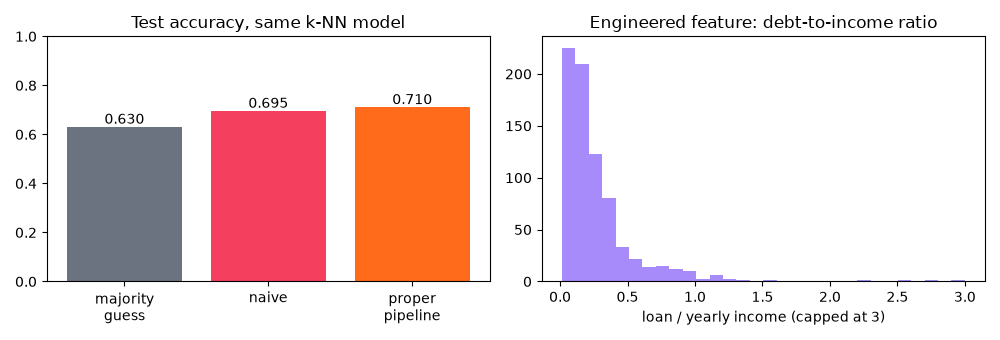

In [7]:
from IPython.display import Image, display
display(Image(filename='session-13_problem_loan_preprocessing.png'))  # chart saved by the cell above

## Example: `session-13_project_prep_toolkit.py`

In [8]:
"""
Session 13 · Mini project: a reusable data-preparation toolkit
--------------------------------------------------------------
Three functions you can reuse on ANY tabular dataset:
  quality_report(df)            -> one row per column: type, missing %, unique values, a suggestion
  build_preprocessor(df, target)-> a ColumnTransformer chosen automatically from the column types
  save / load                   -> persist the FITTED pipeline with joblib, reload it later and
                                   transform brand-new rows exactly the same way
Demonstrated on a synthetic customer-churn table for a mobile network.
Run:  python session-13_project_prep_toolkit.py
"""
import os
import joblib
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.width", 140)

def quality_report(df, target=None):
    """Summarise every column and suggest a preprocessing step."""
    rows = []
    for col in df.columns:
        s = df[col]
        missing = s.isna().mean() * 100
        numeric = pd.api.types.is_numeric_dtype(s)
        if col == target:
            tip = "target: never transform with the features"
        elif s.nunique() == len(s):
            tip = "drop: unique ID, no pattern to learn"
        elif not numeric:
            tip = "one-hot encode" if s.nunique() <= 15 else "too many categories: group rare ones"
        elif abs(s.skew()) > 1:
            tip = "skewed: consider log transform, then scale"
        else:
            tip = "scale"
        if missing > 40:
            tip = "mostly missing: consider dropping"
        elif missing > 0:
            tip = ("impute median, " if numeric else "impute mode, ") + tip
        rows.append({"column": col, "dtype": str(s.dtype), "missing_%": round(missing, 1),
                     "unique": s.nunique(), "suggestion": tip})
    return pd.DataFrame(rows)

def build_preprocessor(df, target, drop=()):
    """Pick numeric and categorical columns automatically and wire up the right steps."""
    features = df.drop(columns=[target, *drop])
    num = features.select_dtypes("number").columns.tolist()
    cat = features.select_dtypes(exclude="number").columns.tolist()
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=0.02))]), cat),
    ]), num, cat

# ---------- demo dataset ----------
rng = np.random.default_rng(77)
n = 1000
df = pd.DataFrame({
    "customer_id": [f"C{100000 + i}" for i in range(n)],
    "tenure_months": rng.integers(1, 72, n).astype(float),
    "monthly_bill": rng.lognormal(7.2, 0.5, n).round(0),
    "data_gb": rng.gamma(2, 6, n).round(1),
    "complaints": rng.poisson(0.8, n).astype(float),
    "package": rng.choice(["Prepaid", "Postpaid", "Business"], n, p=[0.6, 0.3, 0.1]),
    "region": rng.choice(["Sindh", "Punjab", "KP", "Balochistan", "ICT"], n, p=[0.3, 0.4, 0.15, 0.05, 0.1]),
    "referral_note": np.where(rng.random(n) < 0.7, None, "friend"),
})
z = -0.5 - 0.04 * df["tenure_months"] + 0.6 * df["complaints"] + (df["package"] == "Prepaid") * 0.9
df["churned"] = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)
df.loc[rng.choice(n, 60, replace=False), "monthly_bill"] = np.nan
df.loc[rng.choice(n, 30, replace=False), "region"] = np.nan

print("=== quality report ===")
print(quality_report(df, target="churned").to_string(index=False))

prep, num, cat = build_preprocessor(df, "churned", drop=["customer_id", "referral_note"])
print("\nnumeric columns    :", num)
print("categorical columns:", cat)

X, y = df.drop(columns="churned"), df["churned"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1)
pipe = Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=1000))]).fit(X_tr, y_tr)
print(f"\nchurn rate {y.mean():.2f} | test accuracy {pipe.score(X_te, y_te):.3f}")
coefs = pd.Series(pipe.named_steps["model"].coef_[0], index=pipe.named_steps["prep"].get_feature_names_out())
print("strongest signals (scaled coefficients):", coefs.sort_values(key=abs, ascending=False).head(4).round(2).to_dict())

# ---------- persist the fitted pipeline and reuse it ----------
joblib.dump(pipe, "churn_pipeline.joblib")
print(f"\nsaved churn_pipeline.joblib ({os.path.getsize('churn_pipeline.joblib') / 1024:.1f} KB)")
reloaded = joblib.load("churn_pipeline.joblib")
new_customers = pd.DataFrame({
    "customer_id": ["C900001", "C900002"], "tenure_months": [3, 60], "monthly_bill": [np.nan, 2400],
    "data_gb": [25, 4], "complaints": [3, 0], "package": ["Prepaid", "Postpaid"],
    "region": ["Gilgit-Baltistan", "Punjab"], "referral_note": [None, None],
})
probs = reloaded.predict_proba(new_customers)[:, 1]
for cid, p in zip(new_customers["customer_id"], probs):
    print(f"  {cid}: churn risk {p:.0%} -> {'offer a retention discount' if p > 0.5 else 'no action'}")
print("same predictions as the original pipeline:", np.allclose(probs, pipe.predict_proba(new_customers)[:, 1]))
os.remove("churn_pipeline.joblib")

=== quality report ===
       column   dtype  missing_%  unique                                                suggestion
  customer_id     str        0.0    1000                      drop: unique ID, no pattern to learn
tenure_months float64        0.0      71                                                     scale
 monthly_bill float64        6.0     762 impute median, skewed: consider log transform, then scale
      data_gb float64        0.0     287                skewed: consider log transform, then scale
   complaints float64        0.0       6                skewed: consider log transform, then scale
      package     str        0.0       3                                            one-hot encode
       region     str        3.0       5                               impute mode, one-hot encode
referral_note     str       70.7       1                         mostly missing: consider dropping
      churned   int64        0.0       2                 target: never transform with 


saved churn_pipeline.joblib (4.6 KB)
  C900001: churn risk 89% -> offer a retention discount
  C900002: churn risk 4% -> no action
same predictions as the original pipeline: True
